# 06 · What It Means for You

**Claim:** the bias-variance U is not wrong, it is *regime-dependent*. It governs models smaller than their data. Modern practice mostly lives on the far side of the threshold, where bigger is often better and interpolation is fine. Regularization still matters on both sides: it is the tool that flattens the peak.

*Double Descent 101 · notebook 6 of 6 · previous: [05 · More data can hurt](05_more_data_can_hurt.ipynb) · back to [01 · The classical U](01_the_classical_u.ipynb)*

In [1]:
import numpy as np
import pandas as pd

from src.config import get_settings
from src.evaluation import aggregate, run_capacity_experiment, summarize_curve, task_for
from src.models.small_net import mlp_width_sweep, torch_available
from src.reporting import publish_figure, save_json
from src.visualisation import (
    INK, INK_2, MODEL_COLORS, SURFACE, TRAIN_COLOR, annotate_point, capacity_axes, format_error,
    new_figure, noise_colors, plot_curve,
)

settings = get_settings()
SIGMA = settings.headline_noise
M = "random_features"
N = settings.random_features.n_train

## Regularization reshapes the curve

Everything so far used the *ridgeless* minimum-norm fit, to show the phenomenon in its rawest form. Ridge regression adds a penalty $\lambda\lVert\theta\rVert^2$ (per training point here: minimise $\frac{1}{n}\lVert y - \Phi\theta\rVert^2 + \lambda\lVert\theta\rVert^2$). As $\lambda \to 0$ it recovers the min-norm fit. This is the connection to [regularization_101](https://github.com/Dima806/regularization_101).

In [2]:
rcfg = settings.ridge
ridge_curves = {}
for lam in rcfg.lambdas:
    df = run_capacity_experiment(M, settings, noise_levels=[SIGMA], n_seeds=rcfg.n_seeds, ridge_lambda=lam)
    ridge_curves[lam] = aggregate(df)
ridge_summary = pd.DataFrame(
    {
        lam: {
            "median at p = n": c.set_index("n_params").loc[N, "median"],
            "best p": int(c.loc[c["median"].idxmin(), "n_params"]),
            "best median MSE": c["median"].min(),
            "peak / best": c["median"].max() / c["median"].min(),
        }
        for lam, c in ridge_curves.items()
    }
).T
ridge_summary.index.name = "lambda"
ridge_summary.round(3)

,median at p = n,best p,best median MSE,peak / best
lambda,,,,
0.0000,67.225,1722.0,0.253,265.944
0.0001,2.816,1722.0,0.253,11.900
0.0010,0.921,1722.0,0.252,3.806
0.0100,0.365,1722.0,0.250,2.563
0.1000,0.219,285.0,0.202,3.167
1.0000,0.276,814.0,0.160,4.013


{'png': '/workspaces/double_descent_101/outputs/figures/06_ridge_reshapes_curve.png',
 'json': '/workspaces/double_descent_101/outputs/data/06_ridge_reshapes_curve.json'}

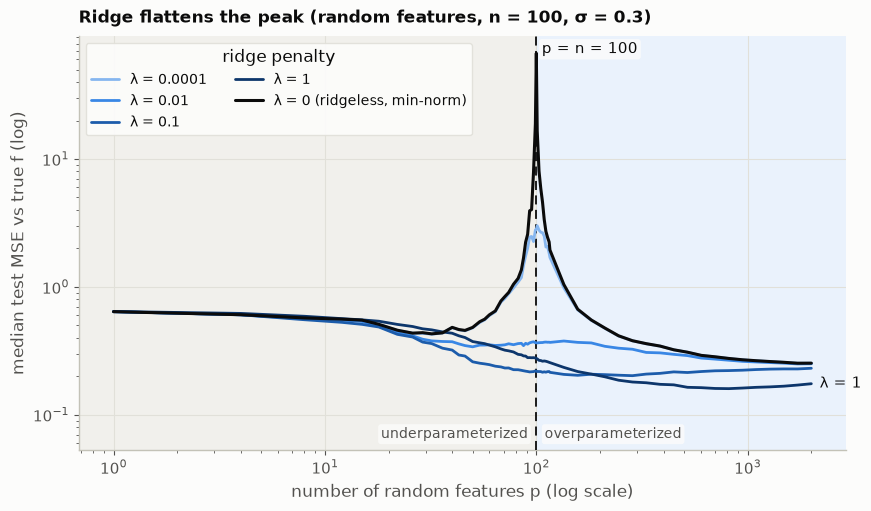

In [3]:
# Plot four well-separated penalties (all of them are in the table above and in the JSON).
shown = [lam for lam in (1e-4, 1e-2, 1e-1, 1.0) if lam in ridge_curves]
cols = dict(zip(shown, noise_colors(shown).values()))
fig, (ax,) = new_figure(width=8.6, height=5.0)
for lam in shown:
    plot_curve(ax, ridge_curves[lam], cols[lam], f"λ = {lam:g}", band=False)
plot_curve(ax, ridge_curves[0.0], INK, "λ = 0 (ridgeless, min-norm)", band=False, lw=2.2)
best = ridge_curves[max(shown)]
ax.annotate(f"λ = {max(shown):g}", xy=(best["n_params"].iloc[-1], best["median"].iloc[-1]), xytext=(6, 0),
            textcoords="offset points", va="center", fontsize=10.5, color=INK)
capacity_axes(ax, N, xlabel="number of random features p (log scale)", ylabel="median test MSE vs true f (log)", logx=True)
ax.set_title(f"Ridge flattens the peak (random features, n = {N}, σ = {SIGMA})", fontsize=12.5)
ax.legend(loc="upper left", fontsize=10, title="ridge penalty", ncols=2)
publish_figure(
    fig, "06_ridge_reshapes_curve", "Ridge flattens the peak",
    f"Median test error over {rcfg.n_seeds} draws for ridge regression on p random features (20-D track, n = {N}, "
    f"σ = {SIGMA}), penalty λ per training point. λ = 0 is the min-norm fit used everywhere else.",
    {"noise": SIGMA, "n_train": N, "n_seeds": rcfg.n_seeds,
     "curves": {f"{lam:g}": {"n_params": c["n_params"].tolist(), "median": c["median"].tolist()} for lam, c in ridge_curves.items()},
     "summary": ridge_summary.reset_index()},
)

Three lessons in one picture:

1. **Even a whisper of ridge kills most of the peak.** $\lambda = 10^{-4}$ already cuts it by an order of magnitude, and by $\lambda = 10^{-2}$ it is gone. The peak exists because the ridgeless fit is willing to use enormous coefficients at $p = n$, and any penalty on coefficient size takes that option away.
2. **A well-tuned penalty is better than ridgeless.** With $\lambda = 0.1$ the curve is nearly monotone and matches or beats ridgeless at every size. More capacity is simply better. $\lambda = 1$ reaches the lowest error of all (about 0.16, against the ridgeless floor of 0.25). Nakkiran et al. (2021) show that optimally tuned ridge can remove double descent entirely in settings like this.
3. **Too much penalty underfits.** $\lambda = 1$ is up to about 13% *worse* than ridgeless for small models ($p \lesssim n/3$), which is the classical tradeoff again.

So regularization is not obsolete. It decides whether the threshold region is a cliff or a gentle slope.

## Not just linear models: a tiny trained network

Random features freeze the first layer. Does a network that **trains both layers** show the same curve? One hidden ReLU layer, full-batch Adam, no weight decay, no early stopping, the same 20-D task with $n = 100$. Here $p = 22 \cdot \text{width} + 1$, so the threshold sits near width 4–5. This needs the optional `torch` extra.

In [4]:
mcfg = settings.mlp
mlp_ok = torch_available()
if mlp_ok:
    mlp = mlp_width_sweep(task_for(M, settings), n_train=mcfg.n_train, widths=mcfg.widths, noise=mcfg.noise,
                          epochs=mcfg.epochs, learning_rate=mcfg.learning_rate, n_seeds=mcfg.n_seeds,
                          seed=settings.seed, threads=mcfg.threads)
    mlp_test = aggregate(mlp)
    mlp_train = aggregate(mlp, value="train_mse")
    peak_row = mlp_test.loc[mlp_test["median"].idxmax()]
    display(mlp_test.merge(mlp_train[["n_params", "median"]], on="n_params", suffixes=("_test", "_train"))
            [["n_params", "median_test", "median_train"]].round(4))
else:
    print("torch is not installed (uv sync --extra torch); skipping the MLP confirmation.")

,n_params,median_test,median_train
0,23,0.1220,0.1330
1,45,0.2153,0.1133
2,67,0.3448,0.0476
3,89,0.5702,0.0118
4,111,0.9600,0.0001
5,133,0.8218,0.0001
6,155,0.5264,0.0000
7,199,0.4330,0.0000
8,287,0.3734,0.0000
9,507,0.3584,0.0000


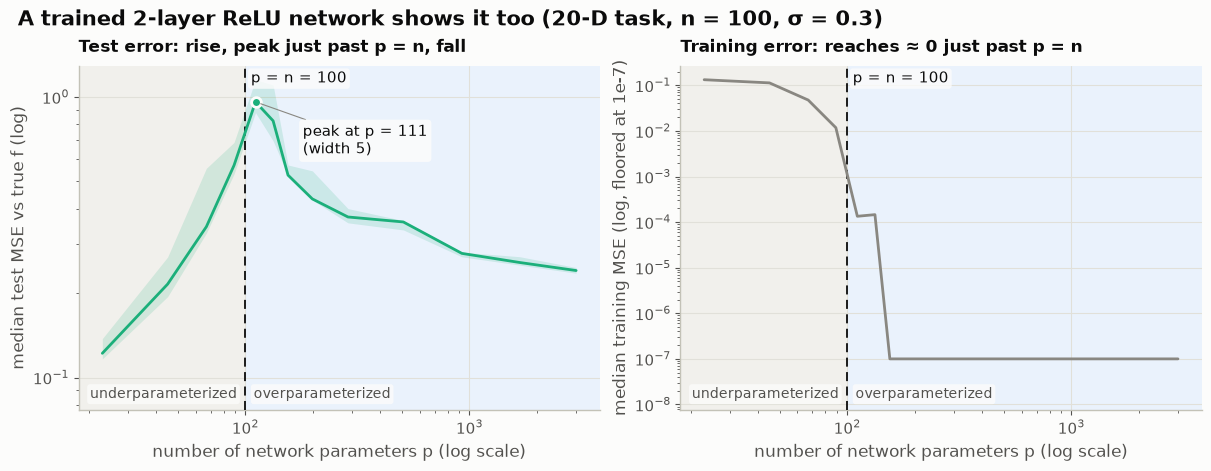

In [5]:
if mlp_ok:
    fig, axes = new_figure(ncols=2, width=12.0, height=4.6)
    plot_curve(axes[0], mlp_test, MODEL_COLORS["mlp"], None)
    capacity_axes(axes[0], mcfg.n_train, xlabel="number of network parameters p (log scale)",
                  ylabel="median test MSE vs true f (log)", logx=True)
    annotate_point(axes[0], peak_row["n_params"], peak_row["median"],
                   f"peak at p = {int(peak_row['n_params'])}\n(width {int(mlp.loc[mlp['n_params'] == peak_row['n_params'], 'capacity'].iloc[0])})",
                   dx=34, dy=-28, color=MODEL_COLORS["mlp"])
    axes[0].set_title("Test error: rise, peak just past p = n, fall", fontsize=12.5)
    plot_curve(axes[1], mlp_train.assign(median=np.maximum(mlp_train["median"], 1e-7)), TRAIN_COLOR, None, band=False)
    capacity_axes(axes[1], mcfg.n_train, xlabel="number of network parameters p (log scale)",
                  ylabel="median training MSE (log, floored at 1e-7)", logx=True)
    axes[1].set_title("Training error: reaches ≈ 0 just past p = n", fontsize=12.5)
    fig.suptitle(f"A trained 2-layer ReLU network shows it too (20-D task, n = {mcfg.n_train}, σ = {mcfg.noise})",
                 x=0.01, ha="left")
    publish_figure(
        fig, "06_tiny_mlp", "A trained network shows it too",
        f"Median over {mcfg.n_seeds} draws of a one-hidden-layer ReLU network with both layers trained by full-batch Adam "
        f"({mcfg.epochs} epochs, no weight decay) on the 20-D task, n = {mcfg.n_train}, σ = {mcfg.noise}. "
        "Training error is floored at 1e-7 for display.",
        {"n_train": mcfg.n_train, "noise": mcfg.noise, "widths": mcfg.widths, "n_params": mlp_test["n_params"].tolist(),
         "test_median": mlp_test["median"].tolist(), "train_median": mlp_train["median"].tolist(),
         "peak": {"n_params": int(peak_row["n_params"]), "median_test_mse": float(peak_row["median"])}},
    )

The same rise-peak-fall shape appears with nothing frozen. The error is lowest for the tiniest network, because a single hidden unit is already a decent model of a single-direction target. It then rises to a peak just past $p = n$, exactly where the network first manages to drive training error to about zero, and falls again (from about 0.96 to 0.24) as the network widens far beyond the data. Two honest differences from the linear models:

- The peak sits **near**, not exactly at, $p = n$. A trained network's effective capacity depends on optimisation, not just on its parameter count (Nakkiran et al., 2020).
- On this target the second descent does **not** beat the tiniest network, because one ReLU unit already nearly matches a single-direction target. The shape is general. Whether the far side wins depends on the problem.

## The framework

One picture to keep: where you are relative to the threshold tells you which rule applies.

{'png': '/workspaces/double_descent_101/outputs/figures/06_regime_map.png',
 'json': '/workspaces/double_descent_101/outputs/data/06_regime_map.json'}

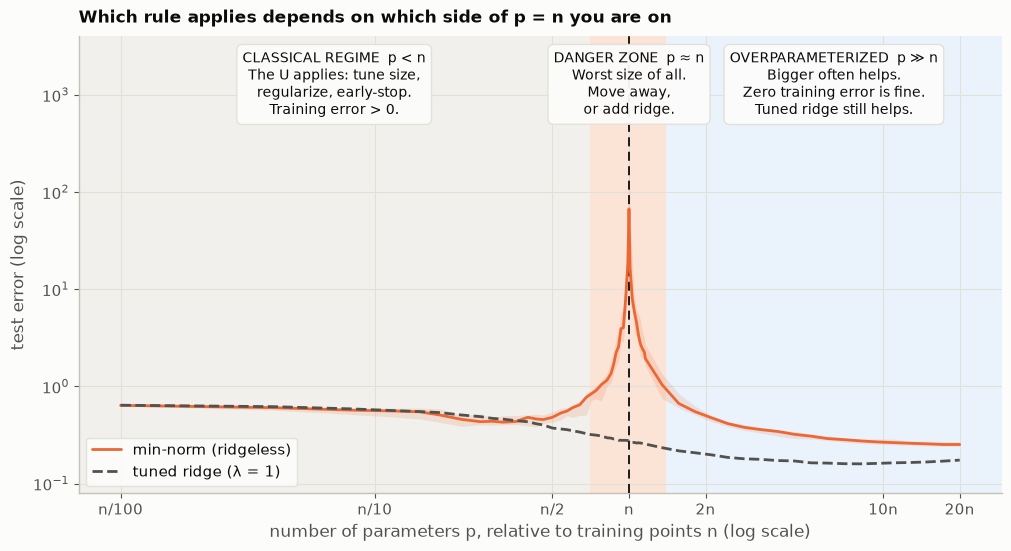

In [6]:
base = ridge_curves[0.0]
best_lam = float(ridge_summary["best median MSE"].idxmin())
summ = summarize_curve(base, N)
fig, (ax,) = new_figure(width=10.0, height=5.4)
plot_curve(ax, base, MODEL_COLORS[M], "min-norm (ridgeless)")
plot_curve(ax, ridge_curves[best_lam], INK_2, f"tuned ridge (λ = {best_lam:g})", band=False, ls="--")
capacity_axes(ax, N, xlabel="number of parameters p, relative to training points n (log scale)",
              ylabel="test error (log scale)", logx=True, regimes=False, threshold_label="")
lo, hi = ax.get_xlim()
zones = [(lo, 0.7 * N, "#f1f0ec"), (0.7 * N, 1.4 * N, "#fbe3d6"), (1.4 * N, hi, "#eaf2fc")]
for a, b, c in zones:
    ax.axvspan(a, b, color=c, lw=0, zorder=0)
ax.set_xlim(lo, hi)
box = {"boxstyle": "round,pad=0.4", "fc": SURFACE, "ec": "#e1e0d9", "alpha": 0.95}
texts = [
    (np.sqrt(lo * 0.7 * N), "CLASSICAL REGIME  p < n\nThe U applies: tune size,\nregularize, early-stop.\nTraining error > 0."),
    (N, "DANGER ZONE  p ≈ n\nWorst size of all.\nMove away,\nor add ridge."),
    (np.sqrt(1.4 * N * hi), "OVERPARAMETERIZED  p ≫ n\nBigger often helps.\nZero training error is fine.\nTuned ridge still helps."),
]
for x, txt in texts:
    ax.annotate(txt, xy=(x, 0.97), xycoords=("data", "axes fraction"), ha="center", va="top", fontsize=10.2,
                color=INK, bbox=box, zorder=7)
ax.set_xticks([N / 100, N / 10, N / 2, N, 2 * N, 10 * N, 20 * N],
              ["n/100", "n/10", "n/2", "n", "2n", "10n", "20n"])
ax.minorticks_off()
ax.set_ylim(0.08, 4000)
ax.legend(loc="lower left", fontsize=10.5)
ax.set_title("Which rule applies depends on which side of p = n you are on", fontsize=12.5)
publish_figure(
    fig, "06_regime_map", "The regime map",
    f"Median test error of min-norm random-feature regression (20-D track, n = {N}, σ = {SIGMA}) and of ridge with "
    f"the best penalty tried (λ = {best_lam:g}), with the three regimes and the rule that applies in each.",
    {"noise": SIGMA, "n_train": N, "n_params": base["n_params"].tolist(), "ridgeless_median": base["median"].tolist(),
     "tuned_ridge_lambda": best_lam, "tuned_ridge_median": ridge_curves[best_lam]["median"].tolist(),
     "zones": {"classical": "p < 0.7 n", "danger": "0.7 n <= p <= 1.4 n", "overparameterized": "p > 1.4 n"},
     "advice": [t for _, t in texts]},
)

## A working checklist

- **Know your ratio.** Compute $p/n$ (parameters, or effective capacity, over training examples) before reasoning about overfitting. The classical intuition is calibrated for $p/n < 1$.
- **Small models ($p < n$):** the U-curve, cross-validated capacity, early stopping and regularization all behave as taught.
- **Near the threshold ($p \approx n$):** expect erratic, noise-dominated test error. It is a predictable peak, not bad luck. Do not "add a little more data" or "a few more parameters" here and expect monotone gains. Add ridge, or move well away from $p = n$.
- **Large models ($p \gg n$):** zero training error is not a red flag on its own, and more capacity often helps, *especially* in high dimensions. But which interpolant your method picks (feature scaling, architecture, optimiser) decides whether overfitting is benign, and tuned regularization usually still improves things.
- **Measure, don't assume.** Everything here came from sweeps you can rerun on your own problem with `src/`: `run_capacity_experiment`, `data_sweep`, `bias_variance` and the min-norm solver.

**Further reading:** Belkin et al. (2019, PNAS), Nakkiran et al. (2020, ICLR), Bartlett et al. (2020, PNAS), Hastie et al. (2022, Annals of Statistics), and companion projects [regularization_101](https://github.com/Dima806/regularization_101) (the penalty that flattens the peak), [curse_of_dimensionality_101](https://github.com/Dima806/curse_of_dimensionality_101) (the high-dimensional geometry where benign overfitting lives) and [cv_arena](https://github.com/Dima806/cv_arena) (estimating test error, which is hardest exactly near the threshold).

In [7]:
save_json(
    {
        "notebook": "06_what_it_means_for_you",
        "claim": "The bias-variance U is regime-dependent: it governs p < n; past the threshold bigger is often better; regularization flattens the peak.",
        "settings": {"headline_noise": SIGMA, "n_train": N, "ridge": rcfg.model_dump(), "mlp": mcfg.model_dump(),
                     "seed": settings.seed},
        "results": {
            "ridge_summary": ridge_summary.reset_index(),
            "best_ridge_lambda": best_lam,
            "ridgeless": summ.to_dict(),
            "mlp": ({"peak_n_params": int(peak_row["n_params"]), "peak_median_test_mse": float(peak_row["median"]),
                     "final_median_test_mse": float(mlp_test["median"].iloc[-1]),
                     "first_median_test_mse": float(mlp_test["median"].iloc[0])} if mlp_ok else None),
        },
        "figures": ["06_ridge_reshapes_curve", "06_regime_map"] + (["06_tiny_mlp"] if mlp_ok else []),
        "takeaways": [
            "A small ridge penalty removes most of the interpolation peak; a tuned one beats ridgeless at every size.",
            "A trained two-layer ReLU network shows the same rise-peak-fall shape, with the peak near p = n.",
            "Classical rules govern p < n; near p = n expect a predictable peak; for p >> n bigger often helps and interpolation is fine.",
        ],
        "next": None,
    },
    "06_summary",
)

PosixPath('/workspaces/double_descent_101/outputs/data/06_summary.json')